<a href="https://colab.research.google.com/github/OrastaRakhmatullayeva/Smartphone-screen-time-prediction/blob/main/smartphone_screen_time.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smartphone Screen Time Prediction

I wanted to explore how smartphone usage habits relate to daily screen time. In this project, I use Linear Regression to estimate screen time from five behavioral features.

**Dataset:** [Kaggle Playground Series S6E8](https://www.kaggle.com/competitions/playground-series-s6e8/data)  
**Target:** `daily_screen_time_hours`

## 1. Load the data

Download the dataset from Kaggle. If prompted, enter your Kaggle credentials privately and accept the competition rules first.

In [1]:
%pip install -q opendatasets

In [3]:
import sys
import types

# Python 3.13 removed the 'cgi' module, which opendatasets depends on.
# We mock the 'cgi' module and its 'parse_header' function to prevent ModuleNotFoundError.
if "cgi" not in sys.modules:
    cgi_mock = types.ModuleType("cgi")
    # opendatasets uses cgi.parse_header to extract filenames from headers
    import urllib.request
    cgi_mock.parse_header = urllib.request.parse_header if hasattr(urllib.request, "parse_header") else lambda x: (x, {})
    sys.modules["cgi"] = cgi_mock

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import opendatasets as od
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
path = Path("playground-series-s6e8/train.csv")
if not path.exists():
    od.download("https://www.kaggle.com/competitions/playground-series-s6e8/data")

df = pd.read_csv(path)
print("Dataset shape:", df.shape)
df.head()

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: corpghff
Your Kaggle Key: ··········


100%|██████████| 19.7M/19.7M [00:02<00:00, 10.3MB/s]



Extracting archive ./playground-series-s6e8/playground-series-s6e8.zip to ./playground-series-s6e8
Dataset shape: (691369, 14)


,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 691369 entries, 0 to 691368
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       691369 non-null  int64  
 1   age                      662440 non-null  float64
 2   daily_screen_time_hours  595515 non-null  float64
 3   social_media_hours       557374 non-null  float64
 4   gaming_hours             564548 non-null  float64
 5   work_study_hours         639851 non-null  float64
 6   sleep_hours              646889 non-null  float64
 7   notifications_per_day    623785 non-null  float64
 8   app_opens_per_day        610659 non-null  float64
 9   weekend_screen_time      579306 non-null  float64
 10  gender                   662335 non-null  object 
 11  stress_level             636221 non-null  object 
 12  academic_work_impact     647145 non-null  object 
 13  addicted_label           691369 non-null  int64  
dtypes: f

## 2. Prepare the data

I use the five features from my original experiment. Rows with missing target values are removed rather than assigning them artificial labels. I split the data before calculating any preprocessing statistics.

In [6]:
features = [
    "social_media_hours", "gaming_hours", "app_opens_per_day",
    "notifications_per_day", "weekend_screen_time"
]
target = "daily_screen_time_hours"

data = df.dropna(subset=[target])
X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train = X_train.copy()
X_test = X_test.copy()

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (476412, 5)
Test set: (119103, 5)


## 3. Exploratory data analysis

I inspect missing values, distributions and correlations on the training set.

In [7]:
missing = X_train.isna().mean().mul(100)
missing.sort_values(ascending=False).round(2)

,0
social_media_hours,15.69
gaming_hours,14.73
weekend_screen_time,13.04
app_opens_per_day,11.03
notifications_per_day,9.18


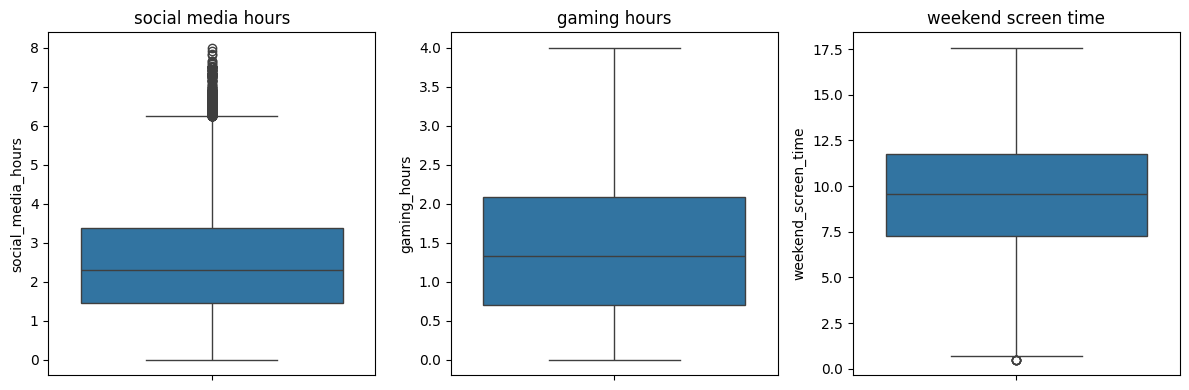

In [8]:
outlier_cols = ["social_media_hours", "gaming_hours", "weekend_screen_time"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for col, ax in zip(outlier_cols, axes):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col.replace("_", " "))
plt.tight_layout()
plt.show()

## 4. Data cleaning

I fill missing feature values with training-set medians and use IQR clipping for the selected time-based features. The same values and limits are applied to the test set to avoid preprocessing leakage.

In [9]:
median = X_train.median()
X_train = X_train.fillna(median)
X_test = X_test.fillna(median)

In [10]:
for col in outlier_cols:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    X_train[col] = X_train[col].clip(lower, upper)
    X_test[col] = X_test[col].clip(lower, upper)

print("Missing training values:", X_train.isna().sum().sum())
print("Missing test values:", X_test.isna().sum().sum())

Missing training values: 0
Missing test values: 0


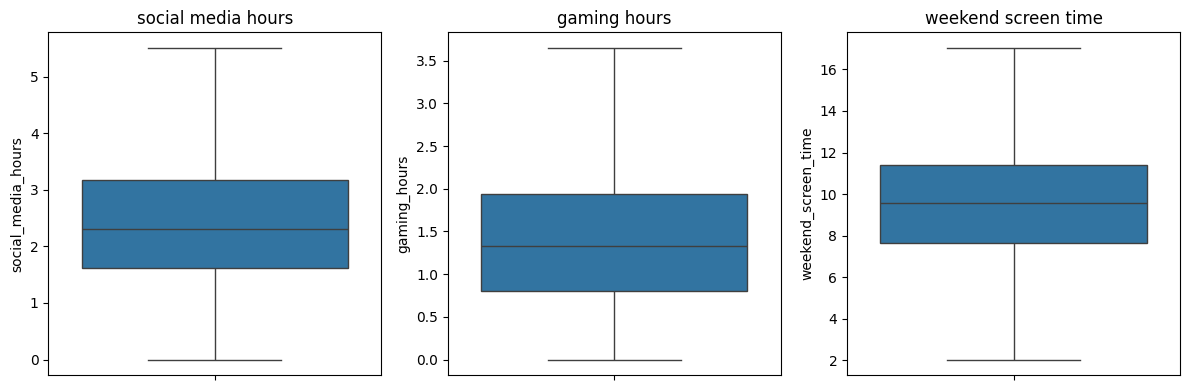

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for col, ax in zip(outlier_cols, axes):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col.replace("_", " "))
plt.tight_layout()
plt.show()

### Feature correlations

The heatmap shows linear relationships between the selected features and daily screen time. Correlation does not imply causation.

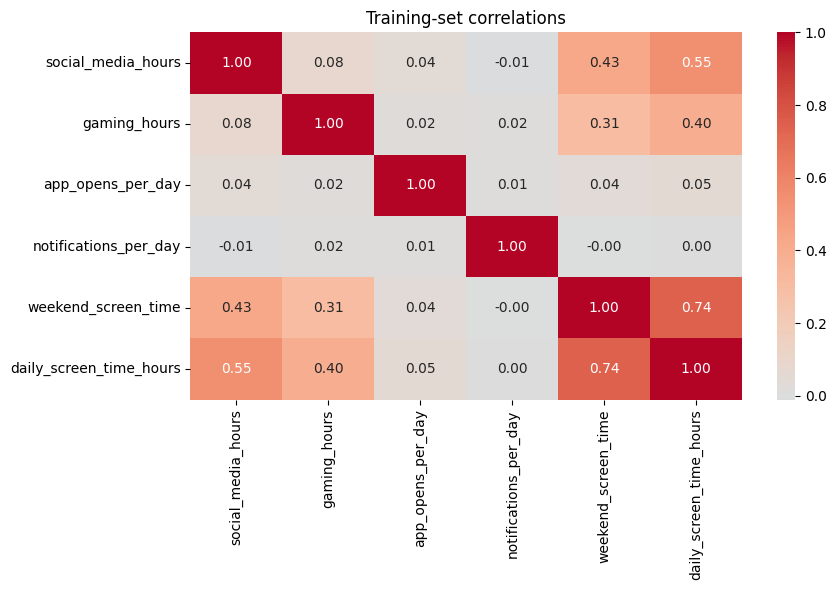

In [12]:
train_data = X_train.copy()
train_data[target] = y_train

plt.figure(figsize=(9, 6))
sns.heatmap(train_data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Training-set correlations")
plt.tight_layout()
plt.show()

## 5. Model training

I chose Linear Regression as a simple, interpretable baseline.

In [13]:
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

## 6. Model evaluation

I use R² to measure explained variation and MAE and RMSE to measure prediction errors in hours. A mean-prediction baseline provides a simple reference point.

In [14]:
r2 = r2_score(y_test, pred)
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))

baseline = np.full(len(y_test), y_train.mean())

results = pd.DataFrame({
    "Model": ["Mean baseline", "Linear Regression"],
    "R²": [r2_score(y_test, baseline), r2],
    "MAE (hours)": [mean_absolute_error(y_test, baseline), mae],
    "RMSE (hours)": [np.sqrt(mean_squared_error(y_test, baseline)), rmse]
})
results.round(4)

,Model,R²,MAE (hours),RMSE (hours)
0,Mean baseline,-0.0000,2.3193,2.7159
1,Linear Regression,0.6539,1.2531,1.5978


### Actual vs. predicted screen time

Points closer to the dashed line represent more accurate predictions. I plot a subset for readability.

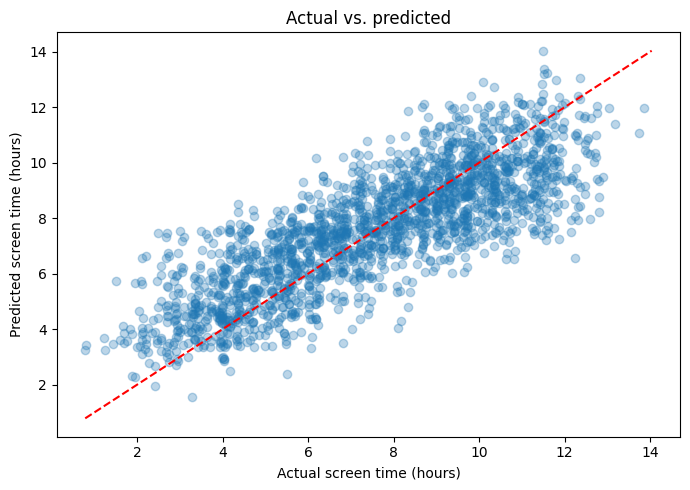

In [15]:
actual = y_test.to_numpy()[:2000]
predicted = pred[:2000]
low = min(actual.min(), predicted.min())
high = max(actual.max(), predicted.max())

plt.figure(figsize=(7, 5))
plt.scatter(actual, predicted, alpha=0.3)
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual screen time (hours)")
plt.ylabel("Predicted screen time (hours)")
plt.title("Actual vs. predicted")
plt.tight_layout()
plt.show()

### Model coefficients

Coefficients describe the estimated change in screen time for a one-unit increase in a feature, holding the others constant. Since features use different units, their coefficient magnitudes are not directly comparable as feature importance.

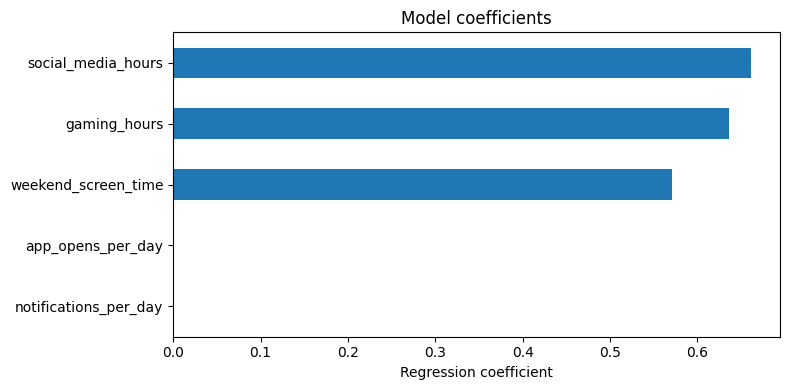

In [16]:
coefficients = pd.Series(model.coef_, index=features)
coefficients.sort_values().plot(kind="barh", figsize=(8, 4))
plt.xlabel("Regression coefficient")
plt.title("Model coefficients")
plt.tight_layout()
plt.show()

## 7. Conclusion

This project helped me practice data cleaning, exploratory analysis and regression on smartphone usage data. Linear Regression provides an interpretable starting point.

The results above describe performance on a held-out split of this dataset. The features were chosen in my earlier experiment, so this is not a completely independent external evaluation. Some usage features may be components of total screen time. The model estimates screen time from available usage information; it does not diagnose addiction or forecast future behavior.

In [17]:
print(f"Linear Regression R²: {r2:.4f}")
print(f"Average absolute error: {mae:.2f} hours")
print(f"RMSE: {rmse:.2f} hours")

Linear Regression R²: 0.6539
Average absolute error: 1.25 hours
RMSE: 1.60 hours
